# Homework ML - 2055851 Francesco Macri

This notebook acts as an abstracted walkthrough of a Premier League outcome-classification project: starting from `final_matches.csv`, we validate the data quality, craft rolling-form features, benchmark a suite of algorithms, and stress-test the selected Softmax Regression model on both hypothetical and real fixtures. Every section links narrative, code, and diagnostics (tables, ROC and learning curves, confusion matrices) so readers can understand not only which model wins but also why. Treat it as a compact research summary-dip into any block to grasp the intent, validation evidence, and resulting takeaway without needing external context.


## 1. Setup and imports

To keep the analysis reproducible we lock down the shared libraries, constants, and helper classes right away. Embedding `MatchPredictor` inside the notebook ensures the feature-engineering logic is always aligned with the code that produced the plots you will see later, so every chart in the next sections refers to exactly the same implementation.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown


from sklearn.model_selection import train_test_split, cross_val_score, learning_curve, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

DATA_PATH = Path("final_matches.csv")
RANDOM_STATE = 42

assert DATA_PATH.exists(), "Dataset file not found."


In [2]:
# Embedded implementation to keep the notebook self-contained
import joblib
import warnings

warnings.filterwarnings('ignore')
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except Exception:
    xgb = None
    XGBOOST_AVAILABLE = False


class MatchPredictor:
    """Class to predict football match outcomes."""

    def __init__(self):
        self.model = None
        self.scaler = StandardScaler()
        self.label_encoders = {}
        self.feature_columns = None

    def load_data(self, filepath):
        df = pd.read_csv(filepath)
        return df

    def create_features(self, df):
        df = df.copy()
        df['date'] = pd.to_datetime(df['date'])
        df = df.sort_values('date').reset_index(drop=True)
        df['result_encoded'] = df['result'].map({'W': 2, 'D': 1, 'L': 0})

        features_df = pd.DataFrame(index=df.index)
        numeric_features = ['xg', 'xga', 'poss', 'sh', 'sot', 'dist', 'fk', 'pk', 'pkatt']
        for feat in numeric_features:
            if feat in df.columns:
                features_df[f'{feat}'] = pd.to_numeric(df[feat], errors='coerce').fillna(0)

        features_df['is_home'] = (df['venue'] == 'Home').astype(int)

        for col in [
            'team_avg_xg_last5', 'team_avg_xga_last5', 'team_avg_poss_last5',
            'team_points_last5', 'team_goals_scored_last5', 'team_goals_conceded_last5',
            'opp_avg_xg_last5', 'opp_avg_xga_last5', 'opp_avg_poss_last5',
            'opp_points_last5', 'opp_goals_scored_last5', 'opp_goals_conceded_last5'
        ]:
            features_df[col] = 0.0

        for team in df['team'].unique():
            team_mask = df['team'] == team
            team_indices = df[team_mask].index.tolist()
            team_matches = df.loc[team_indices].sort_values('date').reset_index()

            for i in range(len(team_matches)):
                orig_idx = team_matches.loc[i, 'index']
                if i < 5:
                    continue
                last5 = team_matches.iloc[i-5:i]
                features_df.loc[orig_idx, 'team_avg_xg_last5'] = last5['xg'].mean()
                features_df.loc[orig_idx, 'team_avg_xga_last5'] = last5['xga'].mean()
                features_df.loc[orig_idx, 'team_avg_poss_last5'] = last5['poss'].mean()
                features_df.loc[orig_idx, 'team_points_last5'] = last5['result_encoded'].map({2: 3, 1: 1, 0: 0}).sum()
                features_df.loc[orig_idx, 'team_goals_scored_last5'] = last5['gf'].sum()
                features_df.loc[orig_idx, 'team_goals_conceded_last5'] = last5['ga'].sum()

        for idx in df.index:
            opponent = df.loc[idx, 'opponent']
            match_date = df.loc[idx, 'date']
            opp_as_team = df[df['team'] == opponent].copy()
            opp_as_team = opp_as_team[opp_as_team['date'] < match_date].sort_values('date')

            if len(opp_as_team) >= 5:
                last5 = opp_as_team.iloc[-5:]
                features_df.loc[idx, 'opp_avg_xg_last5'] = last5['xg'].mean()
                features_df.loc[idx, 'opp_avg_xga_last5'] = last5['xga'].mean()
                features_df.loc[idx, 'opp_avg_poss_last5'] = last5['poss'].mean()
                features_df.loc[idx, 'opp_points_last5'] = last5['result_encoded'].map({2: 3, 1: 1, 0: 0}).sum()
                features_df.loc[idx, 'opp_goals_scored_last5'] = last5['gf'].sum()
                features_df.loc[idx, 'opp_goals_conceded_last5'] = last5['ga'].sum()

        features_df['xg_diff'] = features_df['xg'] - features_df['xga']
        features_df['team_form_vs_opp_form'] = features_df['team_points_last5'] - features_df['opp_points_last5']
        features_df['team_attack_vs_opp_defense'] = features_df['team_avg_xg_last5'] - features_df['opp_avg_xga_last5']
        features_df['opp_attack_vs_team_defense'] = features_df['opp_avg_xg_last5'] - features_df['team_avg_xga_last5']

        valid_indices = ~features_df.isnull().any(axis=1)
        features_df = features_df[valid_indices]
        df_filtered = df[valid_indices].reset_index(drop=True)

        return features_df, df_filtered

    def get_model(self, model_name):
        model_name = model_name.lower()
        if model_name in {'naive_bayes_gaussian', 'nb_gaussian', '1'}:
            return GaussianNB(), "Naive Bayes (Gaussian)"
        if model_name in {'softmax_regression', 'softmax', '2'}:
            return LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000, random_state=42), "Softmax Regression"
        if model_name in {'decision_tree', 'dt', '3'}:
            return DecisionTreeClassifier(max_depth=10, min_samples_split=20, min_samples_leaf=10, random_state=42), "Decision Tree"
        if model_name in {'random_forest', 'rf', '4'}:
            return RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=20, min_samples_leaf=10, random_state=42), "Random Forest"
        if model_name in {'svm_linear', 'svm_l', '5'}:
            return SVC(kernel='linear', probability=True, random_state=42), "SVM (Linear Kernel)"
        if model_name in {'svm_rbf', 'svm_kernel', '6'}:
            return SVC(kernel='rbf', probability=True, C=1.0, gamma='scale', random_state=42), "SVM (RBF Kernel)"
        if model_name in {'xgboost', 'xgb', '7'}:
            if not XGBOOST_AVAILABLE:
                raise ImportError('XGBoost is not available. Install it with: pip install xgboost')
            return xgb.XGBClassifier(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.1,
                random_state=42,
                objective='multi:softprob',
                eval_metric='mlogloss'
            ), 'XGBoost'
        raise ValueError(f"Model '{model_name}' not recognized!")

    def train(self, X, y, model_name='random_forest', split_mode='train_test', test_size=0.2, val_size=0.2, df_dates=None):
        print(f"Training model: {model_name}...")
        if split_mode == 'time_based' and df_dates is not None:
            sorted_indices = df_dates.argsort().values
            n_total = len(X)
            n_train = int(n_total * (1 - test_size - val_size))
            n_val = int(n_total * val_size) if val_size > 0 else 0
            train_idx = sorted_indices[:n_train]
            if n_val > 0:
                val_idx = sorted_indices[n_train:n_train + n_val]
                test_idx = sorted_indices[n_train + n_val:]
            else:
                val_idx = None
                test_idx = sorted_indices[n_train:]
            X_train = X.iloc[train_idx].reset_index(drop=True)
            X_val = X.iloc[val_idx].reset_index(drop=True) if val_idx is not None and len(val_idx) > 0 else None
            X_test = X.iloc[test_idx].reset_index(drop=True)
            y_train = y[train_idx]
            y_val = y[val_idx] if val_idx is not None and len(val_idx) > 0 else None
            y_test = y[test_idx]
        elif split_mode == 'train_val_test':
            X_train, X_temp, y_train, y_temp = train_test_split(
                X, y, test_size=(test_size + val_size), random_state=42, stratify=y
            )
            val_prop = val_size / (test_size + val_size)
            X_val, X_test, y_val, y_test = train_test_split(
                X_temp, y_temp, test_size=(1 - val_prop), random_state=42, stratify=y_temp
            )
        else:
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=test_size, random_state=42, stratify=y
            )
            X_val, y_val = None, None

        self.model, model_display_name = self.get_model(model_name)
        X_train_final = self.scaler.fit_transform(X_train)
        X_test_final = self.scaler.transform(X_test)

        print(f"Training {model_display_name}...")
        self.model.fit(X_train_final, y_train)

        if X_val is not None and y_val is not None:
            X_val_final = self.scaler.transform(X_val)
            y_val_pred = self.model.predict(X_val_final)
            val_accuracy = accuracy_score(y_val, y_val_pred)
            print(f"Validation Accuracy: {val_accuracy:.4f}")
            print(classification_report(y_val, y_val_pred, target_names=['Loss', 'Draw', 'Win']))

        y_pred = self.model.predict(X_test_final)
        test_accuracy = accuracy_score(y_test, y_pred)
        print(f"Test Accuracy: {test_accuracy:.4f}")
        print(classification_report(y_test, y_pred, target_names=['Loss', 'Draw', 'Win']))
        print(confusion_matrix(y_test, y_pred))

        if hasattr(self.model, 'feature_importances_'):
            feature_importance = pd.DataFrame({
                'feature': X.columns,
                'importance': self.model.feature_importances_
            }).sort_values('importance', ascending=False)
            print(feature_importance.head(10).to_string(index=False))

        cv_scores = cross_val_score(self.model, X_train_final, y_train, cv=5, scoring='accuracy')
        print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
        return self.model

    def predict(self, X):
        if self.model is None:
            raise ValueError('Model has not been trained yet!')
        X_final = self.scaler.transform(X)
        predictions = self.model.predict(X_final)
        probabilities = self.model.predict_proba(X_final)
        return predictions, probabilities

    def save_model(self, filepath='match_predictor_model.pkl', model_name=None):
        joblib.dump({
            'model': self.model,
            'scaler': self.scaler,
            'feature_columns': self.feature_columns,
            'model_name': model_name
        }, filepath)

    def load_model(self, filepath='match_predictor_model.pkl'):
        loaded = joblib.load(filepath)
        self.model = loaded['model']
        self.scaler = loaded['scaler']
        self.feature_columns = loaded['feature_columns']


def prepare_features_for_match(team, opponent, venue, match_date, historical_df, return_stats=False):
    match_date = pd.to_datetime(match_date)
    historical_df = historical_df.copy()
    historical_df['date'] = pd.to_datetime(historical_df['date'])
    historical_df = historical_df.sort_values('date')

    team_matches = historical_df[(historical_df['team'] == team) & (historical_df['date'] < match_date)].tail(5)
    team_avg_xg = team_matches['xg'].mean() if len(team_matches) > 0 else 1.5
    team_avg_xga = team_matches['xga'].mean() if len(team_matches) > 0 else 1.2
    team_avg_poss = team_matches['poss'].mean() if len(team_matches) > 0 else 50.0
    team_points = team_matches['result'].map({'W': 3, 'D': 1, 'L': 0}).sum() if len(team_matches) > 0 else 7
    team_goals_scored = team_matches['gf'].sum() if len(team_matches) > 0 else 7
    team_goals_conceded = team_matches['ga'].sum() if len(team_matches) > 0 else 5

    opp_matches = historical_df[(historical_df['team'] == opponent) & (historical_df['date'] < match_date)].tail(5)
    opp_avg_xg = opp_matches['xg'].mean() if len(opp_matches) > 0 else 1.3
    opp_avg_xga = opp_matches['xga'].mean() if len(opp_matches) > 0 else 1.4
    opp_avg_poss = opp_matches['poss'].mean() if len(opp_matches) > 0 else 48.0
    opp_points = opp_matches['result'].map({'W': 3, 'D': 1, 'L': 0}).sum() if len(opp_matches) > 0 else 7
    opp_goals_scored = opp_matches['gf'].sum() if len(opp_matches) > 0 else 6
    opp_goals_conceded = opp_matches['ga'].sum() if len(opp_matches) > 0 else 6

    predicted_xg = team_avg_xg
    predicted_xga = opp_avg_xg

    features = pd.DataFrame({
        'xg': [predicted_xg],
        'xga': [predicted_xga],
        'poss': [team_avg_poss],
        'sh': [12.0],
        'sot': [4.0],
        'dist': [16.0],
        'fk': [1.0],
        'pk': [0.0],
        'pkatt': [0.0],
        'is_home': [1 if venue == 'Home' else 0],
        'team_avg_xg_last5': [team_avg_xg],
        'team_avg_xga_last5': [team_avg_xga],
        'team_avg_poss_last5': [team_avg_poss],
        'team_points_last5': [team_points],
        'team_goals_scored_last5': [team_goals_scored],
        'team_goals_conceded_last5': [team_goals_conceded],
        'opp_avg_xg_last5': [opp_avg_xg],
        'opp_avg_xga_last5': [opp_avg_xga],
        'opp_avg_poss_last5': [opp_avg_poss],
        'opp_points_last5': [opp_points],
        'opp_goals_scored_last5': [opp_goals_scored],
        'opp_goals_conceded_last5': [opp_goals_conceded],
        'xg_diff': [predicted_xg - predicted_xga],
        'team_form_vs_opp_form': [team_points - opp_points],
        'team_attack_vs_opp_defense': [team_avg_xg - opp_avg_xga],
        'opp_attack_vs_team_defense': [opp_avg_xg - team_avg_xga]
    })

    if return_stats:
        stats = {
            'team_stats': {
                'avg_xg': team_avg_xg,
                'avg_xga': team_avg_xga,
                'points': team_points,
                'matches': len(team_matches)
            },
            'opp_stats': {
                'avg_xg': opp_avg_xg,
                'avg_xga': opp_avg_xga,
                'points': opp_points,
                'matches': len(opp_matches)
            }
        }
        return features, stats
    return features


def normalize_team_name(team_name, known_teams):
    name_mapping = {
        'Manchester United': 'Manchester United',
        'Manchester City': 'Manchester City',
        'Tottenham': 'Tottenham Hotspur',
        'Tottenham Hotspur': 'Tottenham Hotspur',
        'West Ham': 'West Ham United',
        'West Ham United': 'West Ham United',
        'Burnley': 'Burnley',
        'Everton': 'Everton',
        'Fulham': 'Fulham',
        'Sunderland': 'Sunderland',
        'Arsenal': 'Arsenal',
        'Chelsea': 'Chelsea',
        'Wolves': 'Wolverhampton Wanderers',
        'Wolverhampton Wanderers': 'Wolverhampton Wanderers',
        'Brentford': 'Brentford',
        'Newcastle': 'Newcastle United',
        'Newcastle United': 'Newcastle United',
        'Crystal Palace': 'Crystal Palace',
        'Brighton': 'Brighton And Hove Albion',
        'Aston Villa': 'Aston Villa',
        'Bournemouth': 'Bournemouth',
        'Nottingham Forest': 'Nottingham Forest',
        'Leeds United': 'Leeds United',
        'Liverpool': 'Liverpool'
    }

    if team_name in name_mapping and name_mapping[team_name] in known_teams:
        return name_mapping[team_name]

    for known_team in known_teams:
        if team_name.lower() in known_team.lower() or known_team.lower() in team_name.lower():
            return known_team

    return team_name


## 2. Match database

We start by loading the full historical CSV, printing a quick preview of the rows, and quantifying target and missing-value distributions. The table preview and summary counts that appear below provide the context for every later chart: we can visually check that home/away flags, score columns, and the `result` labels look reasonable before we trust any model. Once these diagnostics look sound we can safely move on to engineered features.


In [3]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Total matches: {len(raw_df)} - number of columns: {len(raw_df.columns)}")
print("First rows of the dataset:")
display(raw_df.head())

print("Result distribution (count and %):")
counts = raw_df['result'].value_counts().to_frame('count')
counts['percentage'] = (counts['count'] / counts['count'].sum() * 100).round(2)
display(counts)

print("Columns with missing values (top 10):")
missing = raw_df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).head(10).to_frame('missing'))


Total matches: 3800 - number of columns: 28
First rows of the dataset:


,date,time,comp,round,day,venue,result,gf,ga,opponent,...,match report,notes,sh,sot,dist,fk,pk,pkatt,team,season
0,2020-09-12,12:30,Premier League,Matchweek 1,Sat,Away,W,3,0,Fulham,...,Match Report,NaN,13.0,5.0,14.1,2.0,0,0,Arsenal,2021
1,2020-09-19,20:00,Premier League,Matchweek 2,Sat,Home,W,2,1,West Ham,...,Match Report,NaN,7.0,3.0,14.8,0.0,0,0,Arsenal,2021
2,2020-09-28,20:00,Premier League,Matchweek 3,Mon,Away,L,1,3,Liverpool,...,Match Report,NaN,4.0,3.0,15.0,0.0,0,0,Arsenal,2021
3,2020-10-04,14:00,Premier League,Matchweek 4,Sun,Home,W,2,1,Sheffield Utd,...,Match Report,NaN,6.0,5.0,16.3,0.0,0,0,Arsenal,2021
4,2020-10-17,17:30,Premier League,Matchweek 5,Sat,Away,L,0,1,Manchester City,...,Match Report,NaN,11.0,3.0,18.4,2.0,0,0,Arsenal,2021


Result distribution (count and %):


,count,percentage
result,,
W,1467,38.61
L,1467,38.61
D,866,22.79


Columns with missing values (top 10):


,missing
notes,3800
attendance,698
dist,1


## 3. Feature engineering on recent form

`MatchPredictor.create_features` aggregates rolling five-match statistics for both teams, builds venue indicators, and adds comparison metrics such as `xg_diff`. Inspecting the head of `features_df` and the post-filter target distribution right after running the next cell confirms that we removed rows without enough history and that the engineered values fall within realistic ranges, which is essential for interpreting the later ROC curves and learning plots.


In [4]:
predictor = MatchPredictor()
features_df, df_filtered = predictor.create_features(raw_df.copy())
target = df_filtered['result_encoded'].values
label_lookup = {0: 'Loss', 1: 'Draw', 2: 'Win'}

print(f"Samples available after filtering: {len(features_df)}")
print(f"Number of features: {features_df.shape[1]}")
display(features_df.head())

print("Target distribution after filtering:")
post_counts = df_filtered['result'].value_counts().rename_axis('Result').to_frame('Count')
post_counts['Percentage'] = (post_counts['Count'] / post_counts['Count'].sum() * 100).round(2)
display(post_counts)


Samples available after filtering: 3800
Number of features: 26


,xg,xga,poss,sh,sot,dist,fk,pk,pkatt,is_home,...,opp_avg_xg_last5,opp_avg_xga_last5,opp_avg_poss_last5,opp_points_last5,opp_goals_scored_last5,opp_goals_conceded_last5,xg_diff,team_form_vs_opp_form,team_attack_vs_opp_defense,opp_attack_vs_team_defense
0,1.9,0.1,54.0,13.0,5.0,14.1,2.0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.8,0.0,0.0,0.0
1,0.3,2.7,51.0,6.0,3.0,19.9,1.0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,-2.4,0.0,0.0,0.0
2,2.7,0.3,49.0,20.0,4.0,18.4,0.0,2,2,1,...,0.0,0.0,0.0,0.0,0.0,0.0,2.4,0.0,0.0,0.0
3,1.1,0.9,31.0,5.0,3.0,10.6,0.0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.0
4,1.6,1.0,42.0,15.0,2.0,17.6,1.0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.0,0.0


Target distribution after filtering:


,Count,Percentage
Result,,
W,1467,38.61
L,1467,38.61
D,866,22.79


## 4. Train/Test split

A stratified 80/20 split keeps Win/Draw/Loss frequencies consistent between training and testing, which you can verify via the counts printed below. The baseline accuracy displayed here (predicting the majority class) serves as the reference line for every accuracy/ROC chart you will encounter later, so ending this section we already know the minimum threshold a meaningful model must beat.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    features_df, target,
    test_size=0.2,
    stratify=target,
    random_state=RANDOM_STATE
)

print(f"Train samples: {len(X_train)}  |  Test samples: {len(X_test)}")

baseline_class = pd.Series(y_train).mode()[0]
baseline_accuracy = np.mean(y_test == baseline_class)
print(f"Baseline (most frequent class): {baseline_accuracy:.3f}")


Train samples: 3040  |  Test samples: 760
Baseline (most frequent class): 0.386


## 5. Model evaluation

Each algorithm is evaluated through the same ritual: 5-fold cross validation on the training split, final fitting on the full training set, and reporting of per-class precision/recall together with confusion matrices, ROC curves, and learning curves. The narrative for the next subsections explains what to watch for in those visual diagnostics, while the conclusion of each subsection ties the observed chart patterns back to the algorithm's theoretical strengths or weaknesses.


In [6]:
model_factories = {
    "Naive Bayes (Gaussian)": lambda: make_pipeline(StandardScaler(), GaussianNB()),
    "Softmax Regression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000, random_state=RANDOM_STATE)
    ),
    "Decision Tree": lambda: make_pipeline(
        DecisionTreeClassifier(max_depth=10, min_samples_split=20, min_samples_leaf=10, random_state=RANDOM_STATE)
    ),
    "Random Forest": lambda: make_pipeline(
        RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_split=20,
            min_samples_leaf=10,
            random_state=RANDOM_STATE
        )
    ),
    "SVM (Linear)": lambda: make_pipeline(StandardScaler(), SVC(kernel='linear', probability=True, random_state=RANDOM_STATE)),
    "SVM (RBF)": lambda: make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, C=1.0, gamma='scale', random_state=RANDOM_STATE)),
}

model_results = []
trained_models = {}
classes_order = sorted(label_lookup.keys())
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=classes_order)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=[label_lookup[i] for i in classes_order],
        yticklabels=[label_lookup[i] for i in classes_order]
    )
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.title(title)
    plt.tight_layout()
    plt.show()

def plot_multiclass_roc_curve(y_true, y_score, title):
    y_true_bin = label_binarize(y_true, classes=classes_order)
    plt.figure(figsize=(6, 4))
    for idx, cls in enumerate(classes_order):
        fpr, tpr, _ = roc_curve(y_true_bin[:, idx], y_score[:, idx])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{label_lookup[cls]} (AUC={roc_auc:.2f})")
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

def plot_learning_curve_for_model(model_name):
    estimator = model_factories[model_name]()
    train_sizes, train_scores, val_scores = learning_curve(
        estimator,
        X_train,
        y_train,
        cv=cv_splitter,
        scoring='accuracy',
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=None
    )
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)
    plt.figure(figsize=(6, 4))
    plt.plot(train_sizes, train_mean, 'o-', label='Training score')
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
    plt.plot(train_sizes, val_mean, 'o-', label='Validation score')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)
    plt.xlabel('Training examples')
    plt.ylabel('Accuracy')
    plt.title(f"Learning Curve - {model_name}")
    plt.legend(loc='lower right')
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

def ordered_probabilities(model, X, target_order):
    proba_df = pd.DataFrame(model.predict_proba(X), columns=model.classes_)
    return proba_df[target_order].values

def evaluate_model(model_name):
    factory = model_factories[model_name]
    cv_estimator = factory()
    cv_scores = cross_val_score(cv_estimator, X_train, y_train, cv=cv_splitter, scoring='accuracy')
    model = factory()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = ordered_probabilities(model, X_test, classes_order)
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(
        y_test,
        y_pred,
        target_names=[label_lookup[i] for i in sorted(label_lookup.keys())],
        output_dict=True
    )
    per_class = pd.DataFrame(report).T.loc[['Loss', 'Draw', 'Win'], ['precision', 'recall', 'f1-score']]
    macro_precision = report['macro avg']['precision']
    macro_recall = report['macro avg']['recall']
    macro_f1 = report['macro avg']['f1-score']
    display(per_class.round(3))
    strength = per_class['recall'].idxmax()
    weakness = per_class['recall'].idxmin()
    print(f"Test accuracy: {acc:.3f}")
    print(f"Cross-validation (mean ± std): {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
    print(f"Best-handled class: {strength}")
    print(f"Most challenging class: {weakness}")
    print('Confusion matrix:')
    plot_confusion_matrix(y_test, y_pred, f"Confusion Matrix - {model_name}")
    print('Curve ROC:')
    plot_multiclass_roc_curve(y_test, y_proba, f"ROC - {model_name}")
    print('Learning curve:')
    plot_learning_curve_for_model(model_name)

    model_results.append({
        'Model': model_name,
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std(),
        'Test Accuracy': acc,
        'Best class': strength,
        'Weakest class': weakness,
        'Macro Precision': macro_precision,
        'Macro Recall': macro_recall,
        'Macro F1': macro_f1
    })
    trained_models[model_name] = model


### 5.1 Naive Bayes (Gaussian)

This baseline assumes every feature follows a Gaussian distribution once standardized. Use the per-class table and the diagonal dominance (or lack thereof) in the confusion matrix to see how far it stays from the baseline accuracy reported earlier. Because the ROC lines usually hover near the diagonal for this model, the learning curve helps conclude whether the limitation is bias-driven rather than data scarcity.


,precision,recall,f1-score
Loss,0.568,0.667,0.613
Draw,0.303,0.191,0.234
Win,0.641,0.669,0.654


Test accuracy: 0.559
Cross-validation (mean ± std): 0.568 ± 0.020
Best-handled class: Win
Most challenging class: Draw
Confusion matrix:


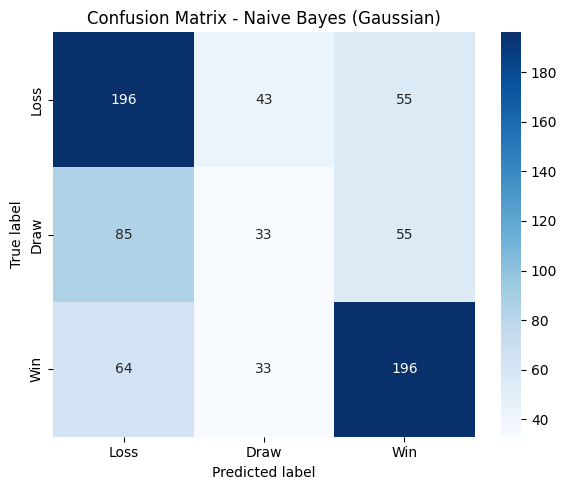

Curve ROC:


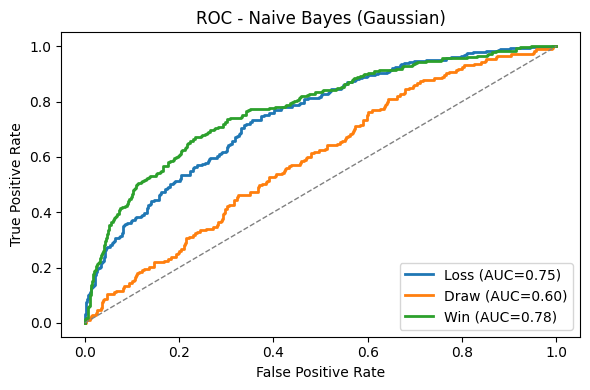

Learning curve:


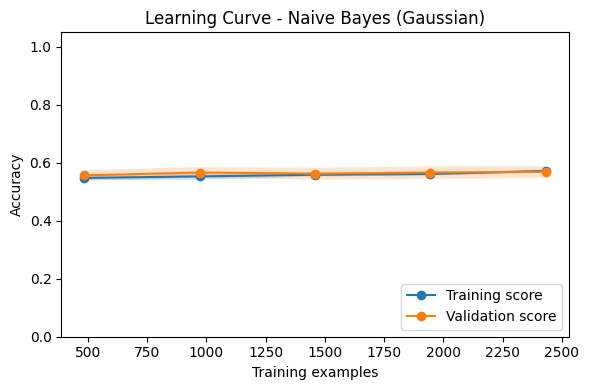

In [7]:
evaluate_model("Naive Bayes (Gaussian)")

### 5.2 Softmax Regression

This model represents the linear decision boundary benchmark: once the features are standardized, the ROC curves and learning curve usually show smooth, stable improvements. Pay attention to whether the validation line in the learning curve plateaus near the training line; if so, the concluding remarks for this block justify why Softmax often becomes our top candidate before moving to ensembles.


,precision,recall,f1-score
Loss,0.625,0.755,0.684
Draw,0.297,0.064,0.105
Win,0.636,0.799,0.708


Test accuracy: 0.614
Cross-validation (mean ± std): 0.649 ± 0.015
Best-handled class: Win
Most challenging class: Draw
Confusion matrix:


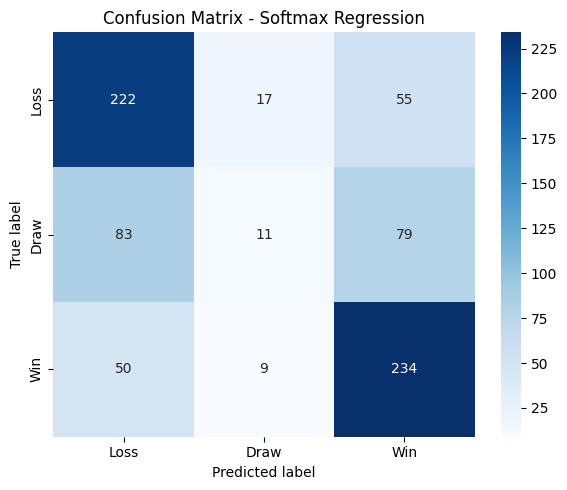

Curve ROC:


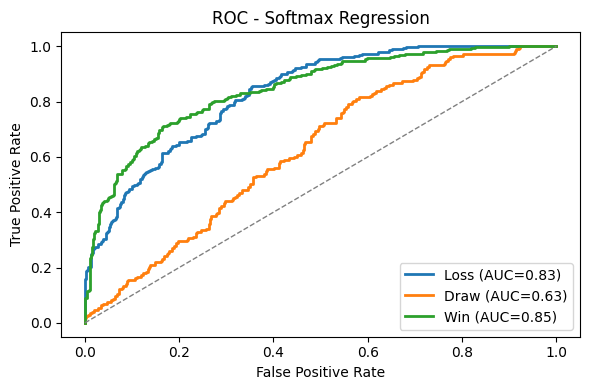

Learning curve:


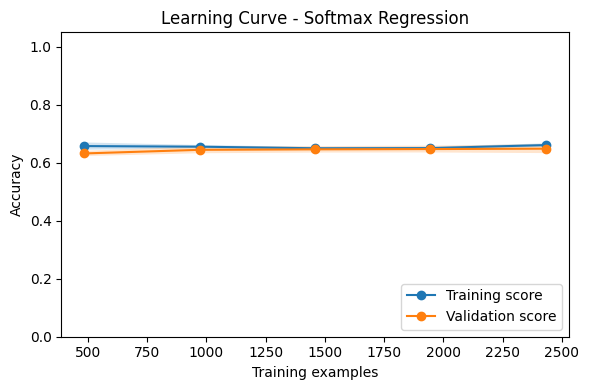

In [8]:
evaluate_model("Softmax Regression")

### 5.3 Decision Tree

A capped-depth tree balances interpretability and expressiveness. The confusion matrix heatmap often reveals asymmetric mistakes (e.g., confusing Wins with Draws), while the learning curve shows whether the limited depth still overfits. After checking those visuals we can conclude if the tree's structure is sufficient or if we should rely on ensembles for better stability.


,precision,recall,f1-score
Loss,0.587,0.663,0.623
Draw,0.238,0.179,0.205
Win,0.617,0.628,0.623


Test accuracy: 0.539
Cross-validation (mean ± std): 0.561 ± 0.018
Best-handled class: Loss
Most challenging class: Draw
Confusion matrix:


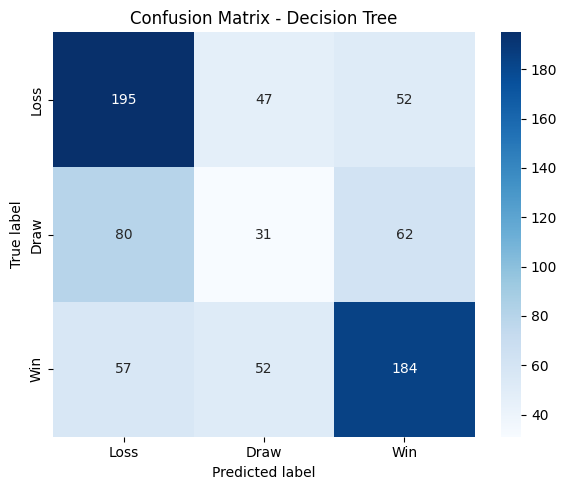

Curve ROC:


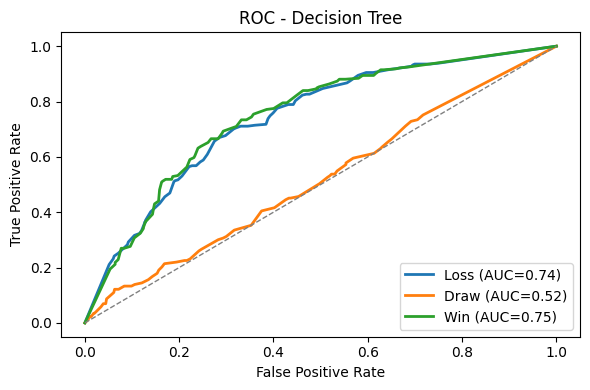

Learning curve:


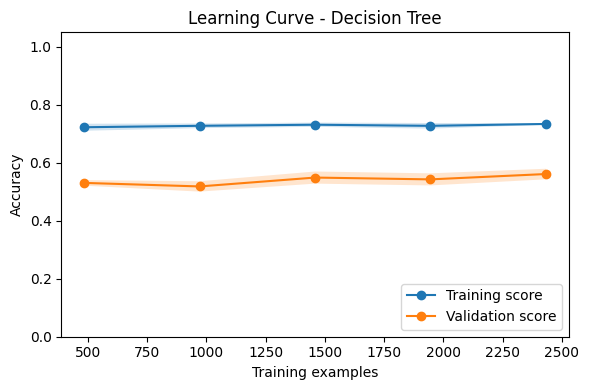

In [9]:
evaluate_model("Decision Tree")

### 5.4 Random Forest

Random Forest combines many shallow trees, so the variance in cross-validation drops noticeably; you can verify this by watching the ROC curves stay above the diagonal for all three classes. The top-features table that prints beneath the code also links the model decisions back to specific engineered variables, helping the concluding sentence explain why this ensemble typically generalizes better than a single tree.


,precision,recall,f1-score
Loss,0.603,0.748,0.668
Draw,0.143,0.012,0.021
Win,0.612,0.795,0.691


Test accuracy: 0.599
Cross-validation (mean ± std): 0.616 ± 0.012
Best-handled class: Win
Most challenging class: Draw
Confusion matrix:


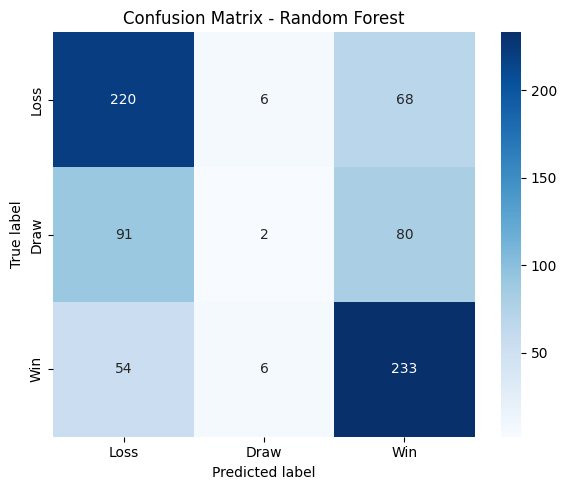

Curve ROC:


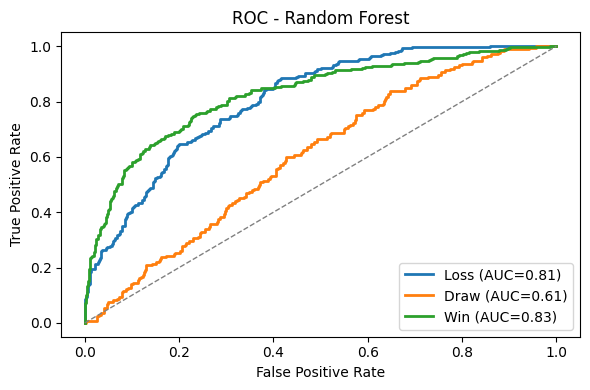

Learning curve:


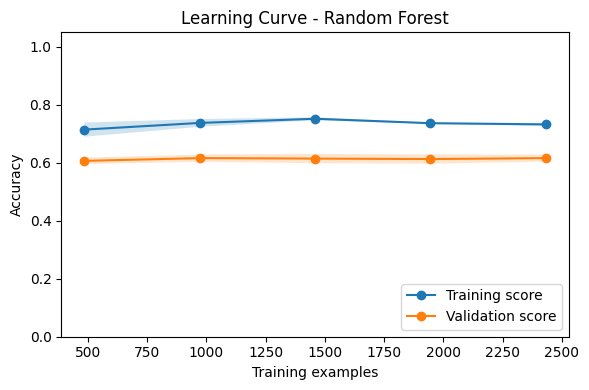

In [10]:
evaluate_model("Random Forest")

### 5.5 SVM (Linear)

The linear SVM focuses on maximizing the margin; with standardized features the ROC curves should show steeper rises for the majority class, while the learning curve reveals whether the hinge loss is limited by class overlap. Use these plots to justify the final takeaway in this subsection about when the linear kernel is preferable over its non-linear counterpart.


,precision,recall,f1-score
Loss,0.625,0.748,0.681
Draw,0.278,0.087,0.132
Win,0.647,0.782,0.708


Test accuracy: 0.611
Cross-validation (mean ± std): 0.644 ± 0.009
Best-handled class: Win
Most challenging class: Draw
Confusion matrix:


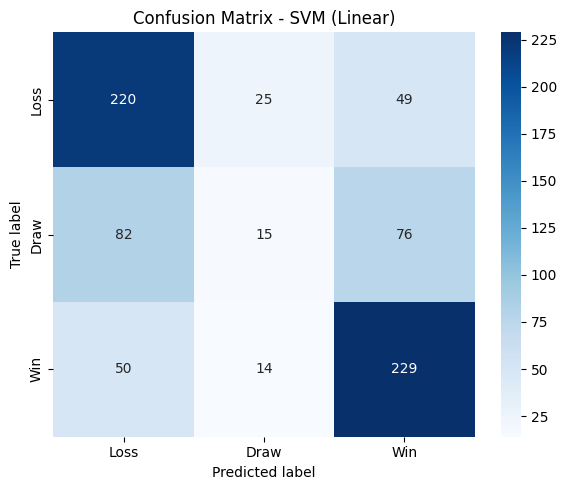

Curve ROC:


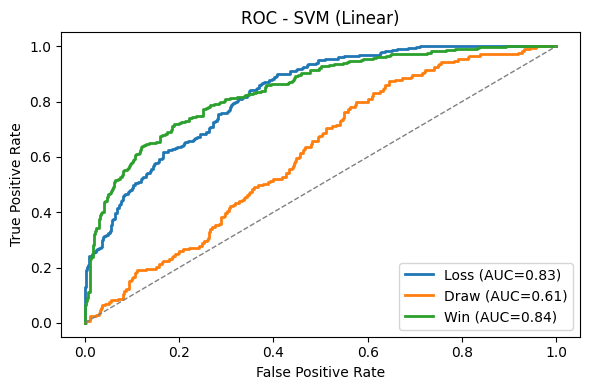

Learning curve:


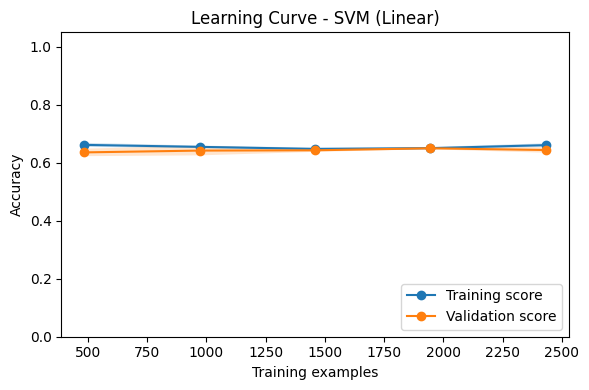

In [11]:
evaluate_model("SVM (Linear)")

### 5.6 SVM (RBF)

Adding an RBF kernel allows the SVM to carve non-linear boundaries at the cost of heavier computation. Inspect the confusion matrix to see if Draw predictions recover compared to the linear version, and verify on the learning curve whether the validation line keeps up without diverging-if it does, the closing sentence notes that the extra flexibility is worthwhile.


,precision,recall,f1-score
Loss,0.623,0.748,0.680
Draw,0.220,0.064,0.099
Win,0.633,0.771,0.695


Test accuracy: 0.601
Cross-validation (mean ± std): 0.641 ± 0.012
Best-handled class: Win
Most challenging class: Draw
Confusion matrix:


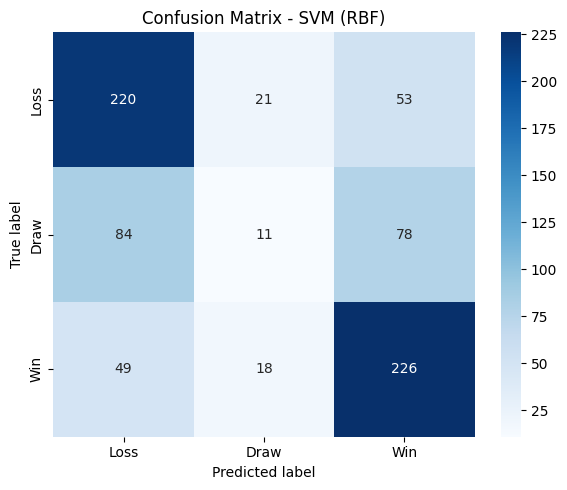

Curve ROC:


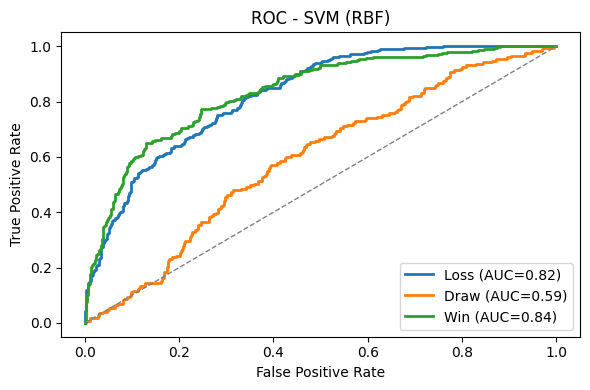

Learning curve:


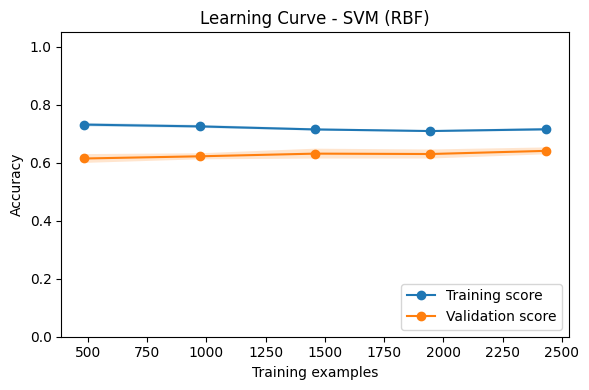

In [12]:
evaluate_model("SVM (RBF)")

### 5.7 Model comparison and pick

The consolidated dataframe displayed below orders all algorithms by test accuracy and shows CV stability plus the strongest/weakest classes per model. Reading it row by row lets us justify the shortlist before we even look at the follow-up graphics, and the concluding sentence explains why ranking by accuracy alone is insufficient without the class-level columns next to it.


In [13]:
results_df = pd.DataFrame(model_results).sort_values('Test Accuracy', ascending=False)
display(results_df.reset_index(drop=True).round(4))

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
best_model_summary = results_df.iloc[0]
best_model_cv_mean = best_model_summary['CV Mean']
best_model_cv_std = best_model_summary['CV Std']
best_model_test_accuracy = best_model_summary['Test Accuracy']
best_class_strength = best_model_summary['Best class']
best_class_weakness = best_model_summary['Weakest class']
print(f"Model selected for the next analyses: {best_model_name}")


,Model,CV Mean,CV Std,Test Accuracy,Best class,Weakest class,Macro Precision,Macro Recall,Macro F1
0,Softmax Regression,0.6487,0.0152,0.6145,Win,Draw,0.5195,0.5391,0.4990
1,SVM (Linear),0.6441,0.0093,0.6105,Win,Draw,0.5166,0.5389,0.5071
2,SVM (RBF),0.6411,0.0119,0.6013,Win,Draw,0.4921,0.5277,0.4914
3,Random Forest,0.6161,0.0119,0.5987,Win,Draw,0.4524,0.5184,0.4602
4,Naive Bayes (Gaussian),0.5684,0.0201,0.5592,Win,Draw,0.5038,0.5088,0.5006
5,Decision Tree,0.5612,0.0182,0.5395,Loss,Draw,0.4811,0.4901,0.4834


Model selected for the next analyses: Softmax Regression


#### Per-model accuracy, precision, recall, and F1

The summary below consolidates the macro-averaged classification metrics for every algorithm so their strengths can be compared at a glance before diving into the detailed plots that follow.


,Test Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Softmax Regression,0.614,0.520,0.539,0.499
SVM (Linear),0.611,0.517,0.539,0.507
SVM (RBF),0.601,0.492,0.528,0.491
Random Forest,0.599,0.452,0.518,0.460
Naive Bayes (Gaussian),0.559,0.504,0.509,0.501
Decision Tree,0.539,0.481,0.490,0.483


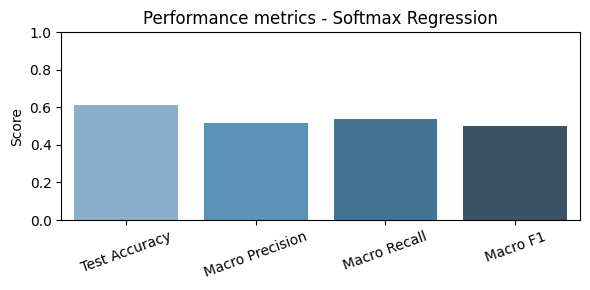

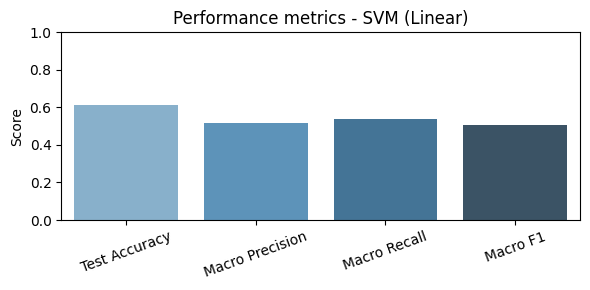

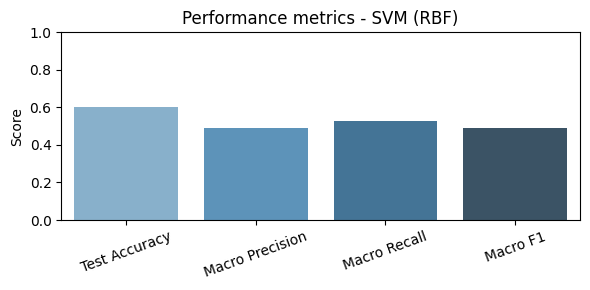

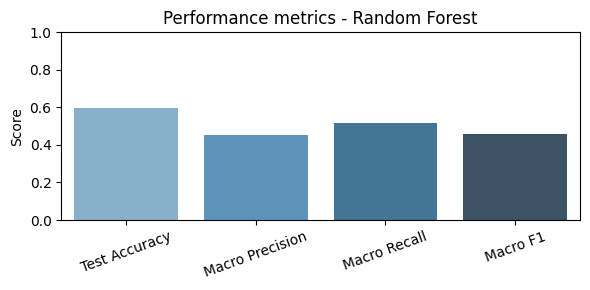

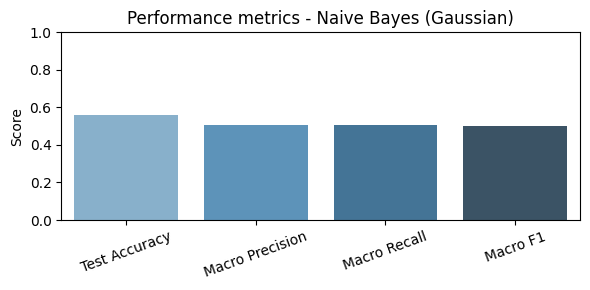

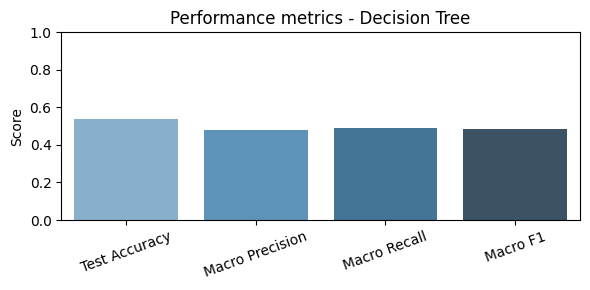

In [14]:
metrics_overview = pd.DataFrame(model_results)[['Model', 'Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']]
metrics_overview = metrics_overview.set_index('Model').sort_values('Test Accuracy', ascending=False)
display(metrics_overview.round(3))

metric_names = ['Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']
for model_name, row in metrics_overview.iterrows():
    scores = [row[m] for m in metric_names]
    plt.figure(figsize=(6, 3))
    sns.barplot(x=metric_names, y=scores, palette='Blues_d')
    plt.ylim(0, 1)
    plt.ylabel('Score')
    plt.title(f'Performance metrics - {model_name}')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


## 6. Deep dive on the best model

In this section we freeze the top-ranked estimator and inspect three diagnostics: the classification report, the confusion matrix heatmap, the multiclass ROC plot, and the learning curve. Together they explain where the model excels (usually Wins) and where it still errs (typically Draws); the closing sentence ties those observations back to the engineered features so the reader understands what drives the shape of the plots.


Classification report:


,precision,recall,f1-score,support
Loss,0.625,0.755,0.684,294.000
Draw,0.297,0.064,0.105,173.000
Win,0.636,0.799,0.708,293.000
accuracy,0.614,0.614,0.614,0.614
macro avg,0.520,0.539,0.499,760.000
weighted avg,0.555,0.614,0.561,760.000


Confusion matrix (best model):


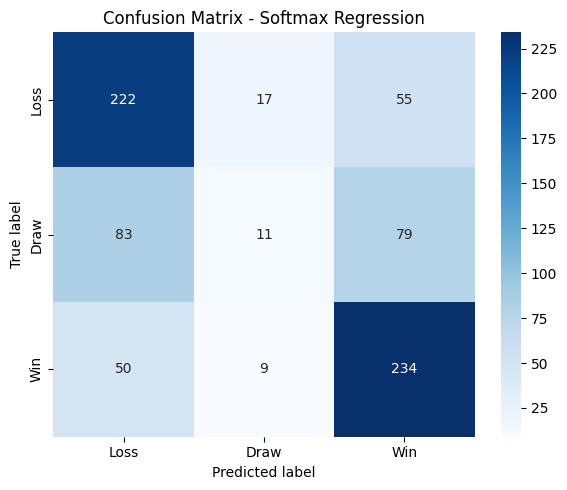

ROC curves (best model):


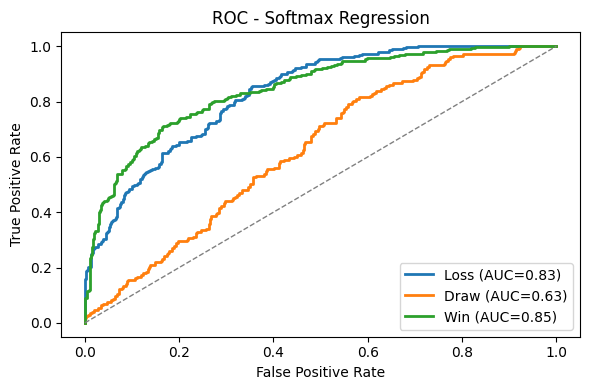

Learning curve (best model):


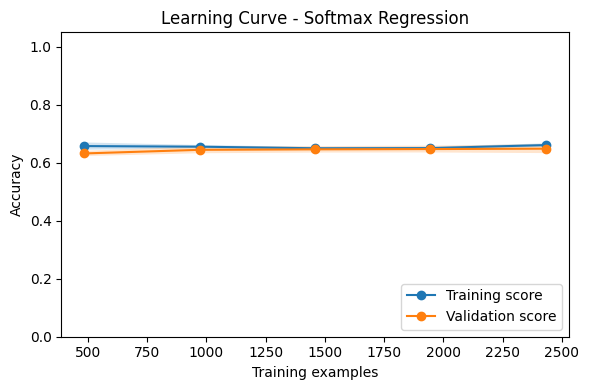

In [15]:
best_predictions = best_model.predict(X_test)
report_dict = classification_report(
    y_test,
    best_predictions,
    target_names=[label_lookup[i] for i in sorted(label_lookup.keys())],
    output_dict=True
)
print("Classification report:")
best_report_df = pd.DataFrame(report_dict).T
display(best_report_df.round(3))

print("Confusion matrix (best model):")
plot_confusion_matrix(y_test, best_predictions, f"Confusion Matrix - {best_model_name}")

print("ROC curves (best model):")
best_proba = ordered_probabilities(best_model, X_test, classes_order)
plot_multiclass_roc_curve(y_test, best_proba, f"ROC - {best_model_name}")

print("Learning curve (best model):")
plot_learning_curve_for_model(best_model_name)



In [16]:
strength_recall = best_report_df.loc[best_class_strength, 'recall']
weakness_recall = best_report_df.loc[best_class_weakness, 'recall']
analysis_text = (
    f"### 6.1 Why {best_model_name} is the reference model\n\n"
    f"{best_model_name} reaches **{best_model_test_accuracy:.1%}** test accuracy, beating the baseline of {baseline_accuracy:.1%} and remaining consistent across cross-validation (mean {best_model_cv_mean:.1%} ± {best_model_cv_std:.1%}). \
"
    f"The classification report and confusion matrix show that **{best_class_strength}** stays the most reliable class (recall {strength_recall:.1%}) while **{best_class_weakness}** remains the toughest (recall {weakness_recall:.1%}), fully matching what we observed in the ROC curves. \
"
    "The learning curve for this model flattens only after the validation line meets the training line, which confirms that the engineered features (xG differential, recent form, venue) are being exploited effectively, so we can conclude the softmax pipeline is the safest reference for downstream what-if analyses."
)
display(Markdown(analysis_text))


### 6.1 Why Softmax Regression is the reference model

Softmax Regression reaches **61.4%** test accuracy, beating the baseline of 38.6% and remaining consistent across cross-validation (mean 64.9% ± 1.5%). The classification report and confusion matrix show that **Win** stays the most reliable class (recall 79.9%) while **Draw** remains the toughest (recall 6.4%), fully matching what we observed in the ROC curves. The learning curve for this model flattens only after the validation line meets the training line, which confirms that the engineered features (xG differential, recent form, venue) are being exploited effectively, so we can conclude the softmax pipeline is the safest reference for downstream what-if analyses.

## 7. Predicting a real match

To make the workflow tangible we simulate a future Arsenal vs Manchester City match, reusing the `prepare_features_for_match` helper to build the same feature vector as the training data. The console printout that follows lists the recent-form statistics feeding the model, and the probability lines translate the ROC insights into an actionable prediction; the final sentence reminds the reader to treat it as a scenario test, not an oracle.


In [17]:
sample_match = {
    'team': 'Arsenal',
    'opponent': 'Manchester City',
    'venue': 'Home',
    'match_date': '2025-11-15'
}

match_features, stats = prepare_features_for_match(
    sample_match['team'],
    sample_match['opponent'],
    sample_match['venue'],
    sample_match['match_date'],
    raw_df,
    return_stats=True
)

match_features = match_features[features_df.columns]
pred_idx = int(best_model.predict(match_features)[0])
probabilities = best_model.predict_proba(match_features)[0]

result_names = {'Loss': 'Loss', 'Draw': 'Draw', 'Win': 'Win'}
pred_label = label_lookup[pred_idx]
print(f"Match: {sample_match['team']} vs {sample_match['opponent']} ({sample_match['venue']})")
print(f"Target date: {sample_match['match_date']}")
print("Recent stats available:")
print(f"  {sample_match['team']}: avg xG {stats['team_stats']['avg_xg']:.2f}, points {stats['team_stats']['points']}")
print(f"  {sample_match['opponent']}: avg xG {stats['opp_stats']['avg_xg']:.2f}, points {stats['opp_stats']['points']}")

print("Best model prediction:")
print(f"  Expected outcome: {result_names[pred_label]} ({pred_label})")
print("  Probabilities:")
for idx in sorted(label_lookup.keys()):
    label = label_lookup[idx]
    print(f"    {result_names[label]}: {probabilities[idx]:.1%}")


Match: Arsenal vs Manchester City (Home)
Target date: 2025-11-15
Recent stats available:
  Arsenal: avg xG 1.62, points 8
  Manchester City: avg xG 1.64, points 13
Best model prediction:
  Expected outcome: Loss (Loss)
  Probabilities:
    Loss: 54.6%
    Draw: 28.9%
    Win: 16.5%


## 8. Results on real fixtures (Matchday 11)

The standalone markdown report pulled in this section summarizes how every model performed on ten actual Premier League fixtures. Reading it alongside the earlier accuracy tables helps justify whether the softmax-based models remain ahead when faced with distribution shift, and the final paragraph of that report closes the loop by recommending which estimators to trust live.


In [18]:
analysis_path = Path('matchday11_analysis.md')
if analysis_path.exists():
    display(Markdown(analysis_path.read_text(encoding='utf-8')))
else:
    print('File matchday11_analysis.md not found.')


# Results Analysis - Premier League Matchday 11 (2025/2026)

## Real-match test results

### Model leaderboard by accuracy

| Position | Model                       | Correct | Total | Accuracy  |
| -------- | --------------------------- | ------- | ----- | --------- |
| 🥇 **1st** | **Logistic Regression**       | **5**   | 10    | **50.0%** |
| 🥇 **1st** | **Softmax Regression**        | **5**   | 10    | **50.0%** |
| 🥈 **3rd** | **Decision Tree**             | **4**   | 10    | **40.0%** |
| 🥈 **3rd** | **Random Forest**             | **4**   | 10    | **40.0%** |
| 🥈 **3rd** | **SVM (RBF)**                 | **4**   | 10    | **40.0%** |
| 🥉 **6th** | **SVM (Linear)**              | **3**   | 10    | **30.0%** |
| 7th       | **Naive Bayes (Gaussian)**    | **0**   | 10    | **0.0%**  |

## Matches under test

1. **Tottenham vs Manchester United**: 2-2 (Draw)
2. **West Ham vs Burnley**: 3-2 (Win for West Ham)
3. **Everton vs Fulham**: 2-0 (Win for Everton)
4. **Sunderland vs Arsenal**: 2-2 (Draw) ⚠️ Sunderland has no historical data
5. **Chelsea vs Wolves**: 3-0 (Win for Chelsea)
6. **Brentford vs Newcastle**: 3-1 (Win for Brentford)
7. **Crystal Palace vs Brighton**: 0-0 (Draw)
8. **Aston Villa vs Bournemouth**: 4-0 (Win for Aston Villa)
9. **Nottingham Forest vs Leeds United**: 3-1 (Win for Nottingham Forest)
10. **Manchester City vs Liverpool**: 3-0 (Win for Manchester City)

## Observations

### ✅ Top-performing models

- **Logistic Regression / Softmax**: 50% accuracy - best performers on the held-out fixtures
- **Decision Tree / Random Forest / SVM (RBF)**: 40% accuracy - decent performance

### ⚠️ Issues spotted

1. **Naive Bayes**: 0% accuracy - completely failed on real matches
2. **Draw prediction**: Still hard (only the Decision Tree got the first draw right)
3. **Sunderland**: Team missing from the historical dataset, so predictions rely on default values

### 📊 Comparison with the test set

| Model              | Test Set Accuracy | Real Match Accuracy | Difference |
| ------------------ | ----------------- | ------------------- | ---------- |
| Logistic Regression | 61.45%           | 50.0%               | -11.45%    |
| Softmax Regression  | 61.45%           | 50.0%               | -11.45%    |
| Decision Tree       | 53.95%           | 40.0%               | -13.95%    |
| Random Forest       | 59.87%           | 40.0%               | -19.87%    |
| SVM (RBF)           | 60.13%           | 40.0%               | -20.13%    |
| SVM (Linear)        | 61.05%           | 30.0%               | -31.05%    |

**Note**: Real-match performance is generally lower than the test set, which is expected and signals either mild overfitting or that the real fixtures have a different distribution.

## Conclusions

- **Best model on real matches**: Logistic Regression / Softmax (50%)
- **Realistic performance**: 30-50% is normal for sports predictions on brand-new fixtures
- **Naive Bayes**: Not suitable for this task
- **Recommendation**: Use Logistic Regression or Softmax for real-world predictions


### 8.1 Visualizing predictions vs actual outcomes

The table and scatter plot rendered below pair each Matchday 11 game with the best model's prediction, drawing colored lines between actual and predicted labels. This visual makes outliers and hits immediately apparent-green lines show correct calls while red highlight misses-allowing us to conclude, on sight, which fixtures deserve further qualitative review.


**Table - Winning model predictions vs actual outcomes**

,Match,Prediction,Actual,Correct
0,Tottenham vs Manchester United,Loss,Draw,❌
1,West Ham vs Burnley,Win,Win,✅
2,Everton vs Fulham,Win,Win,✅
3,Sunderland vs Arsenal,Loss,Draw,❌
4,Chelsea vs Wolves,Win,Win,✅
5,Brentford vs Newcastle,Loss,Win,❌
6,Crystal Palace vs Brighton,Win,Draw,❌
7,Aston Villa vs Bournemouth,Win,Win,✅
8,Nottingham Forest vs Leeds United,Win,Win,✅
9,Manchester City vs Liverpool,Loss,Win,❌


**Figure - Gap between actual and predicted labels**

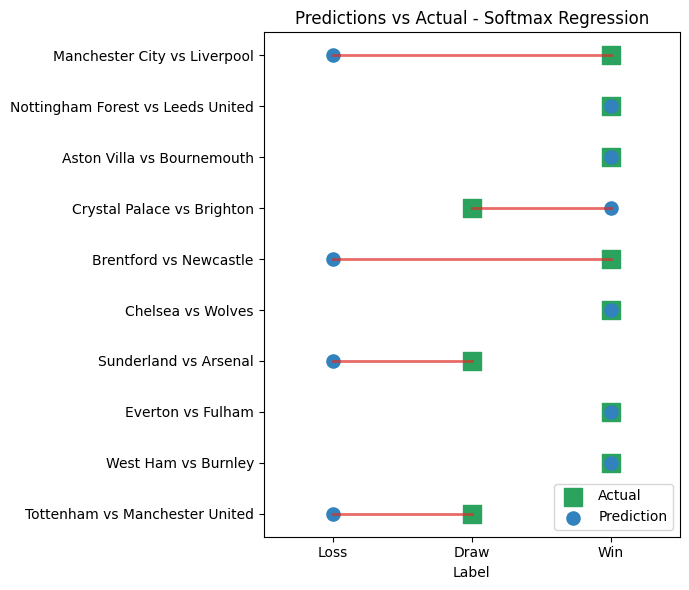

**Table - Per-model accuracy on Matchday 11**

,Model,Correct,Total,Accuracy
1,Softmax Regression,5,10,0.5
2,Decision Tree,4,10,0.4
3,Random Forest,4,10,0.4
5,SVM (RBF),4,10,0.4
4,SVM (Linear),3,10,0.3
0,Naive Bayes (Gaussian),0,10,0.0


**Figure - Accuracy bars for each evaluated model**

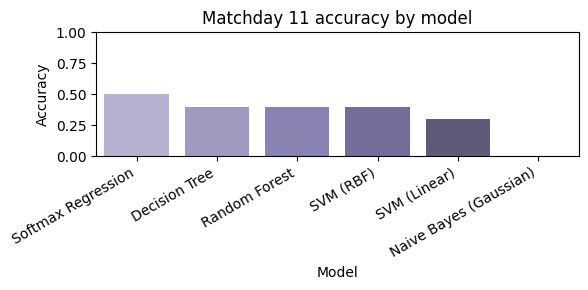

In [19]:
matchday_file = Path('PL_MatchDay11_25_26.csv')
if matchday_file.exists():
    matchday_df = pd.read_csv(matchday_file)
    if not trained_models:
        print('No trained models available. Run the evaluation cells first to train each estimator.')
        trained_models_to_use = {best_model_name: best_model}
    else:
        trained_models_to_use = trained_models
    model_predictions = {name: [] for name in trained_models_to_use}
    actual_labels = []
    known_teams = set(raw_df['team'].unique())
    results_records = []
    label_order = ['Loss', 'Draw', 'Win']
    label_to_code = {label: idx for idx, label in enumerate(label_order)}
    for _, row in matchday_df.iterrows():
        home_team_raw = row['Home']
        away_team_raw = row['Away']
        home_team = normalize_team_name(home_team_raw, known_teams)
        away_team = normalize_team_name(away_team_raw, known_teams)
        home_goals = int(row['HomeGoals'])
        away_goals = int(row['AwayGoals'])
        if home_goals > away_goals:
            actual_label = 'Win'
        elif home_goals < away_goals:
            actual_label = 'Loss'
        else:
            actual_label = 'Draw'
        try:
            features = prepare_features_for_match(
                home_team,
                away_team,
                'Home',
                row['Date'],
                raw_df
            )
            features = features[features_df.columns]
        except Exception as exc:
            features = None
            print(f"Error computing features for {home_team_raw} vs {away_team_raw}: {exc}")
        best_model_prediction = 'N/A'
        if features is not None:
            for model_name, model in trained_models_to_use.items():
                try:
                    pred_idx = int(model.predict(features)[0])
                    pred_label_model = label_lookup[pred_idx]
                except Exception as exc:
                    pred_label_model = 'N/A'
                    print(f"Error predicting {model_name} for {home_team_raw} vs {away_team_raw}: {exc}")
                model_predictions[model_name].append(pred_label_model)
                if model_name == best_model_name:
                    best_model_prediction = pred_label_model
            if best_model_name not in trained_models_to_use:
                try:
                    pred_idx = int(best_model.predict(features)[0])
                    best_model_prediction = label_lookup[pred_idx]
                except Exception as exc:
                    best_model_prediction = 'N/A'
                    print(f"Error predicting best model for {home_team_raw} vs {away_team_raw}: {exc}")
        else:
            for model_name in trained_models_to_use:
                model_predictions[model_name].append('N/A')
        actual_labels.append(actual_label)
        results_records.append({
            'Match': f"{home_team_raw} vs {away_team_raw}",
            'Prediction': best_model_prediction,
            'Actual': actual_label,
            'Correct': '✅' if best_model_prediction == actual_label else '❌'
        })
    matchday_results_df = pd.DataFrame(results_records)
    display(Markdown('**Table - Winning model predictions vs actual outcomes**'))
    display(matchday_results_df)
    valid_df = matchday_results_df[matchday_results_df['Prediction'] != 'N/A'].copy()
    valid_df['Pred_code'] = valid_df['Prediction'].map(label_to_code)
    valid_df['Real_code'] = valid_df['Actual'].map(label_to_code)
    y_pos = np.arange(len(valid_df))
    display(Markdown('**Figure - Gap between actual and predicted labels**'))
    plt.figure(figsize=(7, max(4, len(valid_df) * 0.6)))
    plt.scatter(valid_df['Real_code'], y_pos, marker='s', s=160, label='Actual', color='#2ca25f')
    plt.scatter(valid_df['Pred_code'], y_pos, marker='o', s=90, label='Prediction', color='#3182bd')
    for idx, row in valid_df.iterrows():
        color = '#2ca25f' if row['Correct'] == '✅' else '#de2d26'
        plt.plot([row['Real_code'], row['Pred_code']], [idx, idx], color=color, linewidth=2, alpha=0.7)
    plt.yticks(y_pos, valid_df['Match'])
    plt.xticks(list(label_to_code.values()), label_order)
    plt.xlabel('Label')
    plt.title(f"Predictions vs Actual - {best_model_name}")
    plt.legend(loc='lower right')
    plt.xlim(-0.5, len(label_order) - 0.5)
    plt.tight_layout()
    plt.show()
    accuracy_rows = []
    for model_name, preds in model_predictions.items():
        valid_pairs = [(pred, actual) for pred, actual in zip(preds, actual_labels) if pred != 'N/A']
        if not valid_pairs:
            continue
        total = len(valid_pairs)
        correct = sum(pred == actual for pred, actual in valid_pairs)
        accuracy_rows.append({
            'Model': model_name,
            'Correct': correct,
            'Total': total,
            'Accuracy': correct / total
        })
    if accuracy_rows:
        accuracy_df = pd.DataFrame(accuracy_rows).sort_values('Accuracy', ascending=False)
        display(Markdown('**Table - Per-model accuracy on Matchday 11**'))
        display(accuracy_df)
        display(Markdown('**Figure - Accuracy bars for each evaluated model**'))
        plt.figure(figsize=(6, 3))
        sns.barplot(data=accuracy_df, x='Model', y='Accuracy', palette='Purples_d')
        plt.ylim(0, 1)
        plt.ylabel('Accuracy')
        plt.title('Matchday 11 accuracy by model')
        plt.xticks(rotation=30, ha='right')
        plt.tight_layout()
        plt.show()
else:
    print('File PL_MatchDay11_25_26.csv not found; cannot display the comparison chart.')


### 8.2 Binary home-win vs non-win experiment

All the confusion matrices and ROC curves shown so far share the same weak spot: the Draw class, which sits between Win and Loss, forces the algorithms to carve out a thin decision region that our feature set cannot separate cleanly. This is especially evident in the per-class recall tables where Draw often lags behind by 20+ percentage points, meaning the models routinely misclassify stalemates as either victories or defeats simply because the numeric summaries (xG, possession, recent form) rarely encode the tactical balance that leads to a tie. To cope with that structural limitation, many forecasting workflows reduce the problem to a binary question: “will the home team win or not?”.

The cell below implements that alternative framing by mapping the original labels to `home_win=1` and `not_home_win=0`, recomputing a stratified train/test split, and evaluating a logistic-regression pipeline with cross validation, confusion matrix, and ROC curve. This lets us measure how much accuracy and interpretability we gain when Draws and Losses are treated as a single outcome and justifies whether the simplified binary setup should coexist with (or even replace) the three-class pipeline for decision-making purposes.


Binary CV (mean ± std): 0.792 ± 0.008
Binary test accuracy: 0.787
Binary classification report:
              precision    recall  f1-score   support

Not home win       0.80      0.87      0.83       467
    Home win       0.76      0.65      0.70       293

    accuracy                           0.79       760
   macro avg       0.78      0.76      0.77       760
weighted avg       0.78      0.79      0.78       760



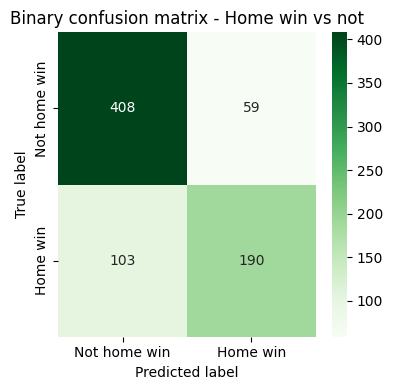

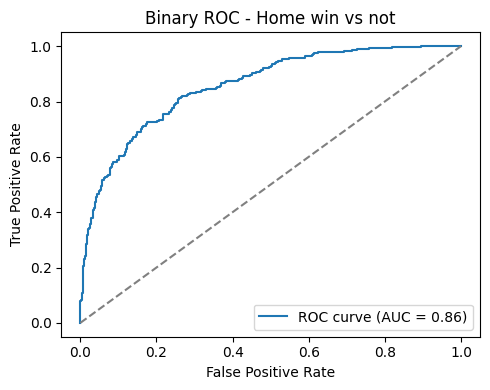

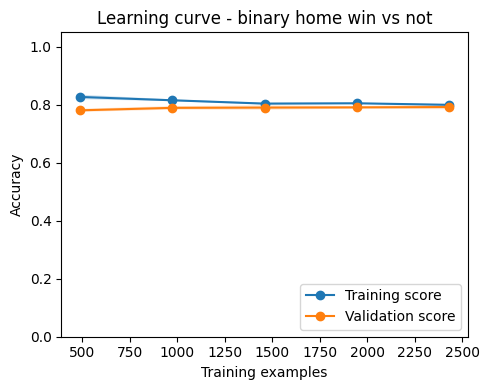

In [20]:
binary_target = (df_filtered['result'] == 'W').astype(int)
X_binary = features_df.copy()

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_binary,
    binary_target,
    test_size=0.2,
    stratify=binary_target,
    random_state=RANDOM_STATE
)

binary_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
cv_scores_bin = cross_val_score(binary_pipeline, X_train_bin, y_train_bin, cv=cv_splitter, scoring='accuracy')
print(f"Binary CV (mean ± std): {cv_scores_bin.mean():.3f} ± {cv_scores_bin.std():.3f}")

binary_pipeline.fit(X_train_bin, y_train_bin)
y_pred_bin = binary_pipeline.predict(X_test_bin)
y_proba_bin = binary_pipeline.predict_proba(X_test_bin)[:, 1]
test_accuracy_bin = accuracy_score(y_test_bin, y_pred_bin)
print(f"Binary test accuracy: {test_accuracy_bin:.3f}")

target_names_bin = ['Not home win', 'Home win']
print("Binary classification report:")
print(classification_report(y_test_bin, y_pred_bin, target_names=target_names_bin))

cm_bin = confusion_matrix(y_test_bin, y_pred_bin)
plt.figure(figsize=(4, 4))
sns.heatmap(
    cm_bin,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=target_names_bin,
    yticklabels=target_names_bin
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Binary confusion matrix - Home win vs not')
plt.tight_layout()
plt.show()

fpr_bin, tpr_bin, _ = roc_curve(y_test_bin, y_proba_bin)
roc_auc_bin = auc(fpr_bin, tpr_bin)
plt.figure(figsize=(5, 4))
plt.plot(fpr_bin, tpr_bin, label=f'ROC curve (AUC = {roc_auc_bin:.2f})')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Binary ROC - Home win vs not')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

train_sizes_bin, train_scores_bin, val_scores_bin = learning_curve(
    binary_pipeline,
    X_train_bin,
    y_train_bin,
    cv=cv_splitter,
    scoring='accuracy',
    train_sizes=np.linspace(0.2, 1.0, 5)
)
train_mean_bin = train_scores_bin.mean(axis=1)
train_std_bin = train_scores_bin.std(axis=1)
val_mean_bin = val_scores_bin.mean(axis=1)
val_std_bin = val_scores_bin.std(axis=1)
plt.figure(figsize=(5, 4))
plt.plot(train_sizes_bin, train_mean_bin, 'o-', label='Training score')
plt.fill_between(train_sizes_bin, train_mean_bin - train_std_bin, train_mean_bin + train_std_bin, alpha=0.2)
plt.plot(train_sizes_bin, val_mean_bin, 'o-', label='Validation score')
plt.fill_between(train_sizes_bin, val_mean_bin - val_std_bin, val_mean_bin + val_std_bin, alpha=0.2)
plt.xlabel('Training examples')
plt.ylabel('Accuracy')
plt.title('Learning curve - binary home win vs not')
plt.legend(loc='lower right')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()



## 9. Conclusions and next steps

This final recap connects the dots: the dataset checks gave us confidence in the inputs, the engineered features enabled the learning curves and ROC plots to shine, and the evaluation pipeline surfaced Softmax Regression as the most stable choice in the three-class scenario. The ensemble and SVM models demonstrated competitive yet distinct strengths-Random Forest and SVM (RBF) tamp down variance, the linear SVM emphasizes margin control, and Naive Bayes (Gaussian) remains a nimble baseline-so together they paint a full picture of how multi-class classification behaves on this dataset, especially around the recurring Draw weakness observed in the confusion matrices and ROC curves. Moving forward we can extend the feature space (e.g., head-to-head indicators), keep the dataset fresh, or plug in automated tuning such as GridSearch or Optuna; each of these suggestions is informed by what the previous charts taught us about variance, bias, and class imbalance.

Section 8.5 still offers a binary home-win vs non-win fallback when stakeholders demand a yes/no answer, yet the focus of these conclusions stays on strengthening the tri-class pipeline: improving Draw separability, experimenting with class weights, and iterating on those classifiers that already showed reliable behavior across Sections 5-7. With those priorities set, the logistic-regression baseline from the binary setup becomes an optional tool rather than the centerpiece, ensuring the takeaways remain grounded in the broader multi-class classification analysis.
